In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

#deviazione standard della media campionaria
def sigma_media(x):
    return x.std(ddof=1, axis=0) / np.sqrt(len(x)), x.mean(axis=0)


[[1100.   1200.    900.   1000.   1050.  ]
 [ 306.7  2926.     10.     58.74  142.6 ]
 [ 377.8  2720.     12.86   48.84  123.8 ]
 [ 552.7  2964.     29.93   77.22  215.3 ]
 [ 358.4  2948.     12.84   44.95  201.1 ]
 [ 327.7  2719.     11.12   56.42  161.9 ]
 [ 403.3  2712.     33.85   78.34  126.7 ]]
[[ 306.7  2926.     10.     58.74  142.6 ]
 [ 377.8  2720.     12.86   48.84  123.8 ]
 [ 552.7  2964.     29.93   77.22  215.3 ]
 [ 358.4  2948.     12.84   44.95  201.1 ]
 [ 327.7  2719.     11.12   56.42  161.9 ]
 [ 403.3  2712.     33.85   78.34  126.7 ]]


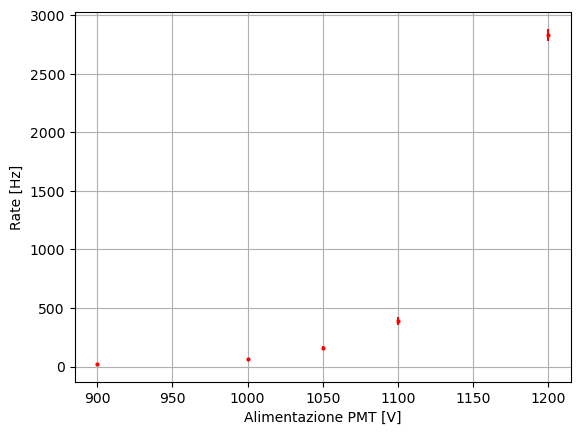

In [166]:
FILE = "Ratebis.txt"

data=np.loadtxt(FILE, unpack=True)
ddp=data[0,:]
r=data[1:,:]

print(data)
print(r)

sigma, media = sigma_media(r)




plt.errorbar(ddp, media , yerr=sigma, fmt="o", markersize=2,color="red")

plt.grid()
plt.xlabel("Alimentazione PMT [V]")
plt.ylabel("Rate [Hz]")


plt.show()

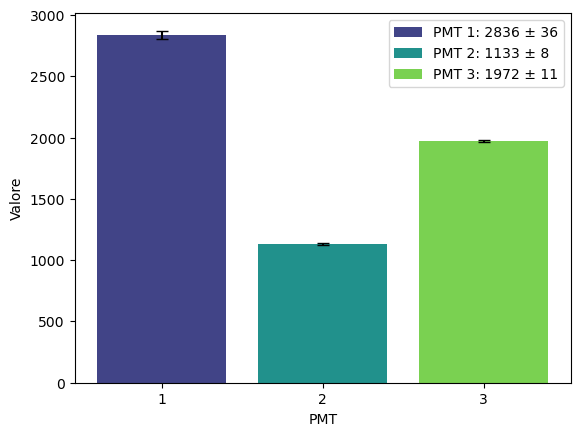

In [26]:
import numpy as np
import matplotlib.pyplot as plt

FILE = "Conteggi scaler.txt"
data = np.loadtxt(FILE, unpack=True)

pmt     = np.asarray(data[0, :]).ravel()
conteggi = data[1:, :]                     


          
sigma,media=sigma_media(conteggi)




colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(pmt)))

fig, ax = plt.subplots()

for i, p in enumerate(pmt):
    ax.bar(
        p, media[i], yerr=sigma[i],
        capsize=4, color=colors[i],
        label=f"PMT {int(p)}: {media[i]:.0f} ± {sigma[i]:.0f}"
    )

ax.set_xticks(pmt)                            
ax.set_xticklabels([str(int(p)) for p in pmt])
ax.set_xlabel("PMT")
ax.set_ylabel("Valore")
ax.legend()

plt.show()

In [8]:
def Rate_netto(Ns, Nb, ts, tb):
    R=(Ns/ts - Nb/tb)
    sigma=np.sqrt(Ns/ts**2 + Nb/tb**2)
    return R, sigma

def Rate_netto_tempo_morto(R_misurato, taud):
    R_netto = R_misurato / (1 + R_misurato * taud)
    return R_netto

def efficienza(N3,N2):
    eff=N3/N2
    sigma_eff=np.sqrt(eff*(1-eff)/N2)
    return eff, sigma

Sigma della poissoniana è sqrt(N), sigma_rel del Rate è 1/sqrt(N)

Numero misure : 54
Media         : 1.556
Varianza      : 1.580
Rapporto var/media : 1.016


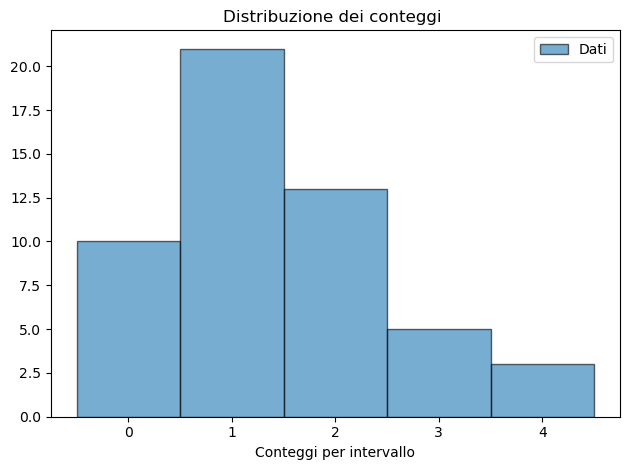

1.2570787221094182


In [4]:
FILE = "statistichebis.txt"
N = np.loadtxt(FILE, unpack=True)



media   = N.mean()
varianza = N.var(ddof=0)
print(f"Numero misure : {len(N)}")
print(f"Media         : {media:.3f}")
print(f"Varianza      : {varianza:.3f}")
print(f"Rapporto var/media : {varianza/media:.3f}")



fig, ax = plt.subplots()

bins = np.arange(N.min() - 0.5, N.max() + 0.5,1  )
ax.hist(N, bins=bins, alpha=0.6, edgecolor="black",
        label="Dati")

k = np.arange(bins[0], bins[-1])
poisson_pmf = stats.poisson.pmf(k, mu=media)
#ax.plot(k, poisson_pmf, "o-", color="red", label=f"Poisson(μ={media:.2f})")

ax.set_xlabel("Conteggi per intervallo")

ax.set_title("Distribuzione dei conteggi ")
ax.legend()
plt.tight_layout()
plt.show()

print(np.sqrt(varianza))

Stessa cosa ma per i tempo con distribuzione esponenziale

[1.         1.         0.5        0.5               inf 0.5
 1.         0.33333333 1.         0.25       0.5               inf
        inf 0.25       1.         1.                inf 0.5
 0.33333333 1.         0.5        0.5        1.         0.2
        inf        inf 1.         0.5        0.5        1.
 0.33333333 1.         0.5        1.         0.5        0.5
 1.         1.         1.         0.33333333 0.2        0.25
 1.         1.         1.         1.         0.33333333        inf
 1.                inf 0.5               inf 1.                inf]
N. intervalli : 54
<dt>          : inf s
Rate          : 0.00 Hz


C:\Users\Sofia\AppData\Local\Temp\ipykernel_26440\2563199174.py:4: RuntimeWarning: divide by zero encountered in divide
  t=1/r
c:\Users\Sofia\anaconda3\Lib\site-packages\numpy\core\function_base.py:158: RuntimeWarning: invalid value encountered in multiply
  y *= step
c:\Users\Sofia\anaconda3\Lib\site-packages\numpy\lib\function_base.py:1452: RuntimeWarning: invalid value encountered in subtract
  a = op(a[slice1], a[slice2])
c:\Users\Sofia\anaconda3\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2076: RuntimeWarning: invalid value encountered in divide
  x = np.asarray((x - loc)/scale, dtype=dtyp)


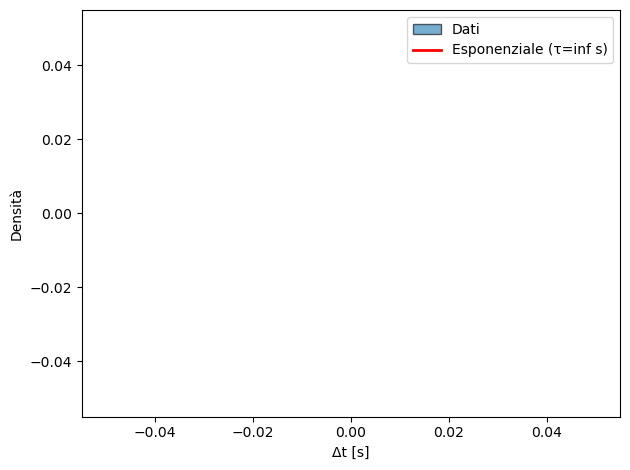

In [12]:
FILE = "statistichebis.txt"
n = np.loadtxt(FILE, unpack=True)  
r=n
t=1/r     

print(t) 


tau = t.mean()

print(f"N. intervalli : {len(t)}")
print(f"<dt>          : {tau:.4f} s")
print(f"Rate          : {1/tau:.2f} Hz")


fig, ax = plt.subplots()
bins = np.linspace(0, np.max(t), 3 )
ax.hist(t, bins=bins, density=True, alpha=0.6, edgecolor="black", label="Dati")

x = np.linspace(0, bins[-1], 300)
ax.plot(x, stats.expon.pdf(x, scale=tau), color="red", lw=2,
        label=f"Esponenziale (τ={tau:.3f} s)")

ax.set_xlabel("Δt [s]")
ax.set_ylabel("Densità")
ax.legend()
plt.tight_layout()
plt.show()



['12' '13' '23' '123']
[[43. 18. 67. 14.]
 [36. 23. 63.  8.]
 [36. 20. 59. 15.]
 [40.  9. 70. 14.]
 [47. 13. 54. 18.]
 [33. 18. 80. 10.]
 [39. 23. 66. 15.]
 [45. 19. 52. 28.]
 [35. 28. 59. 13.]
 [44. 17. 80. 27.]]
[39.8 18.8 65.  16.2]
[1.51143787 1.68522995 3.06594194 2.07525099]


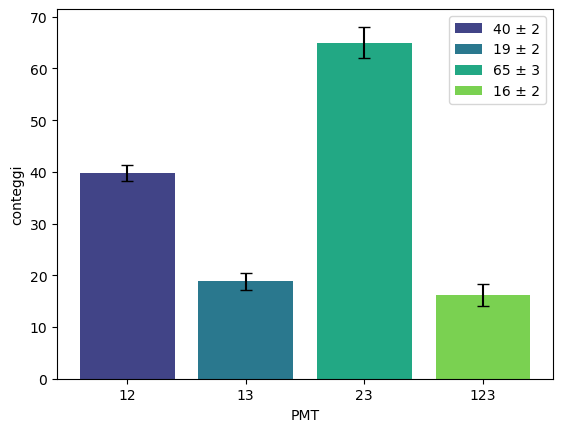

In [39]:
FILE = "coincidenze.txt"
data = np.loadtxt(FILE, unpack=True)

coincidenze= np.asarray(data[1:, :])
combo = data[0, :]    
combo=np.asarray(combo, dtype=int)
combo=np.asarray(combo, dtype=str)
print(combo)
print(coincidenze)
sigma,media=sigma_media(coincidenze)

print(media)
print(sigma)


colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(combo)))

fig, ax = plt.subplots()

for i, p in enumerate(combo):
    ax.bar(
        i , media[i], yerr=sigma[i],
        capsize=4, color=colors[i],
        label=f"{media[i]:.0f} ± {sigma[i]:.0f}"
    )

ax.set_xticks(np.arange(len(combo)))                          
ax.set_xticklabels([str(c) for c in combo])
ax.set_xlabel("PMT")
ax.set_ylabel("conteggi")
ax.legend()

plt.show()


In [85]:
def efficienza(N3,N2):
    eff=N3/N2
    sigma_eff=np.sqrt(eff*(1-eff)/N2)
    return eff, sigma_eff


FILE = "efficienza.txt"
data = np.loadtxt(FILE, unpack=True)

N2=data[0] 
N3=data[1]                 


print(N2,N3)








eff, sigma_eff = efficienza(N3, N2)

print(eff)
print(sigma_eff)
print(sigma_eff/eff)







2112.0 1697.0
0.8035037878787878
0.008646176537818274
0.010760592131922332
0.9486832980505138


[209. 243. 226. 194. 239. 215. 218. 173.] [174. 203. 185. 156. 184. 165.  94.  10.]
[0.83253589 0.83539095 0.81858407 0.80412371 0.76987448 0.76744186
 0.43119266 0.05780347]
[0.02582791 0.02378858 0.02563393 0.02849387 0.0272266  0.02881173
 0.03354208 0.0177429 ]


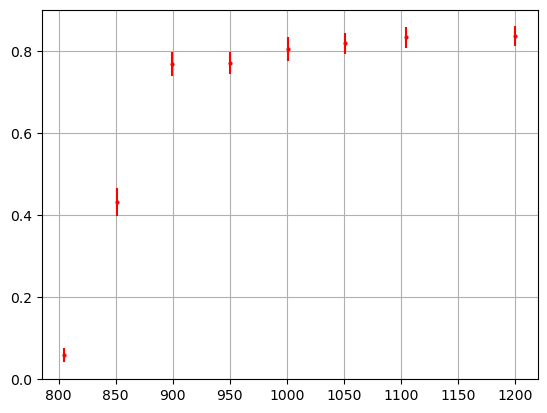

In [121]:
def efficienza(N3,N2):
    eff=N3/N2
    sigma_eff=np.sqrt(eff*(1-eff)/N2)
    return eff, sigma_eff


FILE = "efficienza_V.txt"
data = np.loadtxt(FILE, unpack=True)


N2=data[1] 
N3=data[2]                 
V=data[0]


effs,sigma_effs=efficienza(N3, N2)

print(N2,N3)
print(effs)
print(sigma_effs)


plt.errorbar(V, effs, yerr=sigma_effs, fmt="o", markersize=2, color="red")

plt.grid()

plt.show()


